# ¿Cuándo despega un brote? El umbral R0 = 1

**Pregunta:** Aparece un primer caso en una población donde nadie es inmune. ¿Para qué tasas de contacto y de recuperación inicia un brote, y qué parte de la población debe ser inmune de antemano para que el brote fracase?

- **Nivel:** 1, Fundamentos
- **Requisitos:** tema 01-getting-started
- **Tiempo de lectura:** unos 25 minutos

## Objetivos

Al terminar este notebook puedes decir, solo a partir de $\beta$ y $\gamma$, si un brote despegará; ver el umbral en la salida del motor, tanto en qué tan rápido crecen los infectados la primera semana como en qué tan alto llega el pico; y calcular qué parte de la población debe ser inmune para detenerlo.

## Preparación

El entorno de los notebooks está fijado en `notebooks/requirements.txt` y se construye con `scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows). Los paquetes que usa este notebook, con sus versiones exactas:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

Este producto de ejemplo no publica ningún paquete propio: su método vive en `data-pipeline/pipeline/`, así que el notebook importa ese código por su ruta. Un producto importa su propio paquete de PyPI en su lugar (`pip install <paquete>==<versión>`).

La celda siguiente importa las herramientas y los módulos del pipeline, imprime las versiones y define el lector de los parámetros de los casos.

In [1]:
# las herramientas, sus versiones, los módulos del pipeline y el lector de los parámetros de los casos
import importlib.metadata as md
import json
import sys
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.io.schema import SIRParams
from pipeline.model.baseline import peak_frac
from pipeline.model.sir import simulate

for name in ("numpy", "matplotlib"):
    print(name, md.version(name))


def params_of(case_id):
    manifest = ROOT / "data" / "derived" / "manifests" / f"{case_id}.json"
    return SIRParams(case_id, **json.loads(manifest.read_text(encoding="utf-8"))["params"])


index = json.loads((ROOT / "data" / "derived" / "manifests" / "index.json").read_text(encoding="utf-8"))
CASES = [c["case_id"] for c in index["cases"]]

numpy 2.4.6
matplotlib 3.11.2


## Datos

Los parámetros de los cinco casos del ejemplo.

- Propietario: este repositorio (el ejemplo de la plantilla de producto), https://github.com/fsantibanezleal/CAOS_PRODUCT_TEMPLATE.
- Clase de licencia: datos sintéticos que el pipeline produce a partir de los parámetros de cada manifiesto (`real_or_synthetic` es `synthetic`); no hay un conjunto de datos de terceros, así que no aplica ninguna licencia de datos, y la licencia MIT del repositorio cubre los artefactos.
- Archivos leídos: `data/derived/manifests/index.json` y `data/derived/manifests/<caso>.json`, solo por sus parámetros; cada curva que se muestra aquí la calcula el motor.

## Método

La razón de reproducción básica $R_0$ es el número de personas que infecta una persona infectada, en promedio, en una población donde todos son susceptibles (Diekmann, Heesterbeek y Metz, 1990). En el modelo SIR una persona infectada se encuentra con $\beta$ personas por día y sigue siendo infecciosa durante $1 / \gamma$ días, de modo que $R_0 = \beta / \gamma$. Al comienzo $S \approx N$, la ecuación de los infectados se vuelve $dI/dt \approx (\beta - \gamma) I$, e $I$ crece de forma exponencial a la tasa $\gamma (R_0 - 1)$ cuando $R_0 > 1$ y decae cuando $R_0 < 1$. Bajo las hipótesis de los modelos compartimentales del trabajo citado, $R_0 < 1$ da estabilidad local libre de enfermedad, no una erradicación global incondicional (van den Driessche y Watmough, 2002).

En la aproximación de semilla despreciable, si una parte $v$ es inmune antes del brote, una persona infectada se encuentra con susceptibles solo durante una fracción $(1 - v)$ del tiempo y la razón efectiva es $R_0 (1 - v)$. Baja de 1 cuando $v > 1 - 1/R_0$, el umbral de rebaño. El motor no tiene un compartimento de inmunes, pero inmunizar una parte $v$ equivale a correrlo sobre una población de $(1 - v) N$ personas con la tasa de contacto $\beta (1 - v)$, porque la presión de infección $\beta / N$ queda entonces igual. El notebook usa esa equivalencia.

La primera celda imprime $R_0$ para los cinco casos archivados y, donde supera 1, el umbral de rebaño. No corre ninguna simulación; es la aritmética que el resto del notebook pondrá a prueba contra el motor.

In [2]:
# los cinco casos con R0 = beta / gamma y, donde R0 supera 1, el umbral de rebaño 1 - 1 / R0
for case_id in CASES:
    p = params_of(case_id)
    r0 = p.beta / p.gamma
    threshold = f"{1 - 1 / r0:.3f}" if r0 > 1 else "ninguno (R0 <= 1)"
    print(f"{case_id:18s} R0 = {r0:5.2f}   umbral de rebaño: {threshold}")

CTRL_degenerate    R0 =  2.00   umbral de rebaño: 0.500
EX01_subcritical   R0 =  0.72   umbral de rebaño: ninguno (R0 <= 1)
EX02_epidemic      R0 =  2.75   umbral de rebaño: 0.636
EX03_fast_burn     R0 =  6.00   umbral de rebaño: 0.833
EX04_slow_spread   R0 =  1.20   umbral de rebaño: 0.167


Solo el caso subcrítico, con 0,72, está bajo 1. El control tiene $R_0 = 2{,}00$ pero nadie infectado al principio, así que no hay nada que crezca, y los otros tres tienen $R_0$ de 1,20, 2,75 y 6,00. La celda siguiente corre el motor sobre cada caso con personas infectadas y divide el pico por el número de infectados del día 0. Si $R_0$ es el umbral, el caso subcrítico no debería crecer y los demás deberían crecer en un factor grande.

In [3]:
# corre los casos con infectados y compara cada pico con las personas infectadas al comienzo
for case_id in CASES:
    p = params_of(case_id)
    if p.I0 == 0:
        continue
    r = simulate(p)
    print(f"{case_id:18s} R0 = {p.beta / p.gamma:5.2f}  I0 = {p.I0:4.0f}", end="  ")
    print(f"pico {r.peak_I:7.0f} el día {r.t_peak:6.2f}  x{r.peak_I / p.I0:6.1f}")

EX01_subcritical   R0 =  0.72  I0 =   50  pico      50 el día   0.00  x   1.0
EX02_epidemic      R0 =  2.75  I0 =   50  pico   27345 el día  24.25  x 546.9
EX03_fast_burn     R0 =  6.00  I0 =  100  pico   55265 el día   9.25  x 552.7
EX04_slow_spread   R0 =  1.20  I0 =   50  pico    1521 el día  96.25  x  30.4


El caso subcrítico multiplica sus 50 infecciones iniciales por exactamente 1,0: su pico está en el día 0. La propagación lenta, con un $R_0$ solo 20 por ciento sobre 1, las multiplica por 30, y el caso epidémico y la combustión rápida por unas 550. El umbral se nota, pero tres casos son pocos para ver su forma. La celda siguiente recorre $R_0$ de 0,5 a 4 en pasos de 0,1, con la tasa de recuperación del caso epidémico fija y la tasa de contacto cambiando, y corre el motor en cada valor. Para cada corrida ajusta una recta al logaritmo de los infectados durante la primera semana, cuya pendiente es la tasa de crecimiento observada, y registra el pico como parte de la población. Imprime cuatro valores junto a la teoría: la tasa $\gamma (R_0 - 1)$ y el pico analítico de la línea base.

In [4]:
# recorre R0 de 0,5 a 4 con la tasa de recuperación del caso epidémico, y corre el motor en cada valor
base = params_of("EX02_epidemic")
r0_grid = np.linspace(0.5, 4.0, 36)
growth = []
peak_share = []
for r0 in r0_grid:
    r = simulate(replace(base, beta=r0 * base.gamma))
    growth.append(np.polyfit(r.t[:29], np.log(r.I[:29]), 1)[0])
    peak_share.append(r.peak_I / base.N)
baseline = [peak_frac(r0) for r0 in r0_grid]
for r0 in (0.5, 1.0, 2.0, 4.0):
    k = int(np.argmin(np.abs(r0_grid - r0)))
    print(f"R0 = {r0:3.1f}  crecimiento {growth[k]:+.3f}  gamma (R0 - 1) = {base.gamma * (r0 - 1):+.3f}", end="  ")
    print(f"parte en el pico {peak_share[k]:.4f}  analítico {baseline[k]:.4f}")

R0 = 0.5  crecimiento -0.101  gamma (R0 - 1) = -0.100  parte en el pico 0.0005  analítico 0.0000
R0 = 1.0  crecimiento -0.000  gamma (R0 - 1) = +0.000  parte en el pico 0.0005  analítico 0.0000
R0 = 2.0  crecimiento +0.195  gamma (R0 - 1) = +0.200  parte en el pico 0.1555  analítico 0.1534
R0 = 4.0  crecimiento +0.555  gamma (R0 - 1) = +0.600  parte en el pico 0.4137  analítico 0.4034


La celda siguiente dibuja la tasa de crecimiento y la parte en el pico contra $R_0$ en dos paneles, con el umbral $R_0 = 1$ marcado.

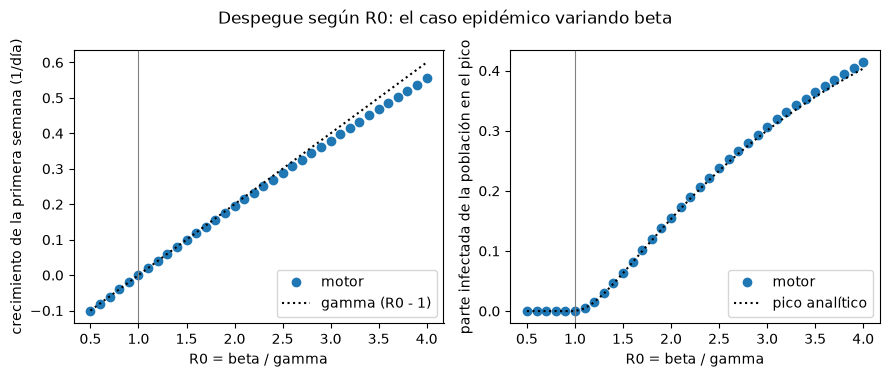

In [5]:
# dibuja el crecimiento de la primera semana y la parte en el pico contra R0, con el umbral R0 = 1
fig, (left, right) = plt.subplots(1, 2, figsize=(9, 3.8))
left.plot(r0_grid, growth, "o", label="motor")
left.plot(r0_grid, base.gamma * (r0_grid - 1), "k:", label="gamma (R0 - 1)")
right.plot(r0_grid, peak_share, "o", label="motor")
right.plot(r0_grid, baseline, "k:", label="pico analítico")
ylabels = ("crecimiento de la primera semana (1/día)", "parte infectada de la población en el pico")
for ax, ylabel in zip((left, right), ylabels):
    ax.axvline(1.0, color="grey", linewidth=0.8)
    ax.set_xlabel("R0 = beta / gamma")
    ax.set_ylabel(ylabel)
    ax.legend()
fig.suptitle("Despegue según R0: el caso epidémico variando beta")
fig.tight_layout()
plt.show()

El panel izquierdo es el umbral mismo: la tasa de crecimiento de la primera semana cruza aproximadamente cerca de $R_0 = 1$ y sigue la recta $\gamma (R_0 - 1)$, un poco por debajo con $R_0$ grande porque al terminar la semana los susceptibles ya han empezado a escasear. El panel derecho muestra qué poco importa una tasa alta justo sobre el umbral: el pico alcanza aproximadamente 1,52 por ciento de la población con $R_0 = 1{,}2$ y luego sube con fuerza, siguiendo el pico analítico de la línea base. La figura no muestra el tiempo. Un brote con $R_0$ apenas sobre 1 sí despega, pero qué tan tarde lo hace es lo que muestra la celda siguiente.

In [6]:
# mira de cerca el umbral: el motor con R0 = 0,9, 1,0, 1,1, 1,2 y 1,5
for r0 in (0.9, 1.0, 1.1, 1.2, 1.5):
    r = simulate(replace(base, beta=r0 * base.gamma))
    print(f"R0 = {r0:3.1f}  pico {r.peak_I:6.0f}  el día {r.t_peak:6.2f}  fracción removida {r.attack_rate:.4f}")
    print(f"pico como porcentaje de N={100*r.peak_I/base.N:.2f}%")

R0 = 0.9  pico     50  el día   0.00  fracción removida 0.0047
pico como porcentaje de N=0.05%
R0 = 1.0  pico     50  el día   0.00  fracción removida 0.0147
pico como porcentaje de N=0.05%
R0 = 1.1  pico    465  el día 160.00  fracción removida 0.0749
pico como porcentaje de N=0.47%
R0 = 1.2  pico   1520  el día 120.25  fracción removida 0.2542
pico como porcentaje de N=1.52%
R0 = 1.5  pico   6379  el día  64.50  fracción removida 0.5845
pico como porcentaje de N=6.38%


Con $R_0 = 0{,}9$ y con $R_0 = 1{,}0$ el pico son las 50 infecciones iniciales del día 0. Con $R_0 = 1{,}1$ los infectados todavía crecen cuando terminan los 160 días: el pico impreso, en el día 160,00, es el último día y no un pico verdadero. Con 1,2 el pico llega en el día 120,25 y con 1,5 en el día 64,50. Justo sobre el umbral el brote existe pero es lento, de modo que un horizonte demasiado corto lo confunde con la ausencia de brote. La última pregunta del notebook es el umbral de rebaño: la celda corre el caso epidémico con una parte $v$ de la población inmune, de 0 a 0,8 en pasos de 0,05, e imprime el umbral $1 - \gamma/\beta$ con la parte infectada para tres valores de $v$.

In [7]:
# Separar removidos e infectados alguna vez bajo inmunidad inicial.
shares = np.linspace(0.0, 0.8, 17)
final_share = []
ever_share = []
for v in shares:
    scaled = replace(base, beta=base.beta * (1 - v), N=base.N * (1 - v))
    immune_run = simulate(scaled)
    final_share.append(immune_run.R[-1] / base.N)
    ever_share.append((immune_run.I[-1] + immune_run.R[-1]) / base.N)
herd = 1 - base.gamma / base.beta
finite_herd = herd - base.I0 / base.N
print(f"umbral de semilla despreciable={herd:.6f}, umbral inicial de semilla finita={finite_herd:.6f}")
for v in (0.3, 0.6, 0.7):
    k = int(np.argmin(np.abs(shares - v)))
    print(f"v={v:.1f}, removidos R(T)/N={final_share[k]:.6f}, alguna vez infectados={ever_share[k]:.6f}")

umbral de semilla despreciable=0.636364, umbral inicial de semilla finita=0.635864
v=0.3, removidos R(T)/N=0.544636, alguna vez infectados=0.544637
v=0.6, removidos R(T)/N=0.049577, alguna vez infectados=0.051423
v=0.7, removidos R(T)/N=0.002777, alguna vez infectados=0.002779


La celda siguiente dibuja la parte infectada contra la parte inmune, con el umbral de rebaño marcado.

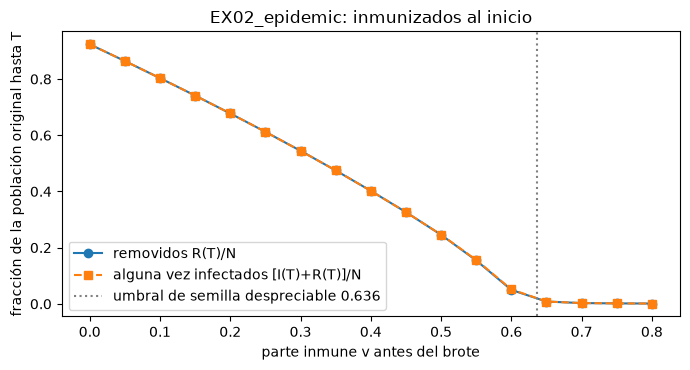

In [8]:
# dibuja la parte infectada de la población contra la parte inmune, con el umbral de rebaño
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(shares, final_share, "o-", label="removidos R(T)/N")
ax.plot(shares, ever_share, "s--", label="alguna vez infectados [I(T)+R(T)]/N")
ax.axvline(herd, color="grey", linestyle=":", label=f"umbral de semilla despreciable {herd:.3f}")
ax.set_xlabel("parte inmune v antes del brote")
ax.set_ylabel("fracción de la población original hasta T")
ax.set_title("EX02_epidemic: inmunizados al inicio")
ax.legend()
fig.tight_layout()
plt.show()

Las dos curvas distinguen removidos R(T)/N de todos los infectados hasta T, [I(T)+R(T)]/N. Cuando el brote no ha terminado, la separación vertical representa a quienes siguen infectados, no error de conservación. Con v=0,3/0,6/0,7 los valores 0,5446/0,0496/0,0028 corresponden a la curva removida, dividida por la población original. La línea vertical usa el umbral de semilla despreciable; el cálculo impreso muestra también la corrección del estado inicial finito. Inmunidad perfecta y homogénea siguen siendo supuestos del escenario, no evidencia de efectividad de una intervención real.

### La fracción inicialmente susceptible precisa el umbral

El criterio de crecimiento se obtiene directamente de la ecuación infectada, sin ajustar trayectorias:

$$\frac{1}{I}\frac{dI}{dt}=\gamma\left(R_0\frac{S}{N}-1\right),\qquad R_{\rm eff}(0)=R_0(1-v-i_0).$$

Aquí $v$ es la fracción inicialmente inmune de la población original e $i_0=I_0/N$ la infectada; ambas deben dejar susceptibles no negativos. Con $v=0$ e $i_0$ despreciable se recupera el umbral habitual de uno. Con semilla no nula, el crecimiento inicial exacto usa $S(0)/N$ real: por eso la tasa de la primera semana solamente cruza aproximadamente en uno. La regresión semanal también promedia agotamiento susceptible y error Euler, mientras la ecuación describe una derivada instantánea.

En el experimento de inmunidad, escalar población y contacto conserva la presión infecciosa sobre quienes no son inmunes. Dividir después por la población original evita confundir una fracción del grupo restante con una fracción de toda la ciudad. La inmunidad inicial perfecta es un escenario SIR construido, no efectividad de vacunas estimada con observaciones. El control sin infecciones es otro límite: una razón reproductiva positiva no crea contagios en una ecuación determinista exactamente sin semilla.

## Resultados

**Respuesta:** Con semilla positiva, el crecimiento instantáneo requiere R0 S(0)/N>1. El umbral R0≈1 supone población inicialmente casi susceptible; la regresión de la primera semana añade agotamiento susceptible y error Euler. Con R0=1,2 el pico alcanza unas 1520 personas, cerca del 1,52 por ciento, no solamente 1 por ciento. Para el caso epidémico el umbral de semilla despreciable es 0,636364 y el umbral inicial con 50 infectados es 0,635864.

Las cantidades 0,5446,0,0496 y0,0028 del experimento de inmunidad corresponden a removidos R(T)/N para v=0,3/0,6/0,7. La columna y la curva adicionales presentan [I(T)+R(T)]/N: cuando quedan infectados, esa fracción es mayor. Todas se dividen por la población original, no por el grupo no inmune reducido. La inmunidad perfecta uniforme y el contacto homogéneo son supuestos construidos, no resultados operacionales ni una garantía global para cualquier estado inicial.

## Resumen

- El criterio instantáneo usa susceptibles iniciales reales y semilla no nula; R0≈1 es el límite casi totalmente susceptible.
- La tasa de primera semana aproxima, sin reproducir exactamente, la derivada inicial.
- Con R0=1,2 el pico llega aproximadamente al 1,52 por ciento; cerca del umbral un horizonte breve puede ocultar su fecha.
- Removidos e infectados alguna vez hasta el horizonte son cantidades distintas.
- La próxima lección estudia el límite final y las condiciones necesarias para compararlo con un corte temporal.

## Referencias

- Diekmann, O., Heesterbeek, J. A. P. y Metz, J. A. J. (1990). On the definition and the computation of the basic reproduction ratio R0 in models for infectious diseases in heterogeneous populations. Journal of Mathematical Biology. https://doi.org/10.1007/BF00178324
- van den Driessche, P. y Watmough, J. (2002). Reproduction numbers and sub-threshold endemic equilibria for compartmental models of disease transmission. Mathematical Biosciences. https://doi.org/10.1016/S0025-5564(02)00108-6
- Kermack, W. O. y McKendrick, A. G. (1927). A contribution to the mathematical theory of epidemics. Proceedings of the Royal Society A. https://doi.org/10.1098/rspa.1927.0118
- NumPy, https://pypi.org/project/numpy/ (fijado en `notebooks/requirements.txt`).
- Matplotlib, https://pypi.org/project/matplotlib/ (fijado en `notebooks/requirements.txt`).
- El motor y la línea base de este repositorio, https://github.com/fsantibanezleal/CAOS_PRODUCT_TEMPLATE (`data-pipeline/pipeline/model/sir.py`, `pipeline/model/baseline.py`).